# Unidad 35 — Serie Pandas para el tratamiento de datos

Semana 5 · Clase 2 · Fuente: PDF parte 2, págs. 75–143

[Índice de la semana](../semana-05.ipynb) | [Anterior](u34-modulos-de-python.ipynb) | [Siguiente](u36-dataframes-de-pandas.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el PDF (pág. 76–77), al terminar la unidad debes ser capaz de:

- Instalar la última versión de la librería pandas en el entorno virtual actual.
- Distinguir entre **Serie** y **DataFrame** cuando se da un conjunto de datos basado en pandas.
- Procesar conjuntos de datos de listas y diccionarios en series (también a partir de arrays de NumPy y de valores escalares).
- Seleccionar un elemento específico de una serie y realizar operaciones aritméticas con series.
- Diferenciar las características de los datos y dibujar un gráfico adecuado (líneas y barras con matplotlib).

**Vocabulario del docente:** *Serie* (pandas) e *Índice*. Palabras clave del PDF: pandas, serie, índice, gráfico lineal, gráfico de barras, elemento de datos.

**Referencia:** PDF parte 2, págs. 76–78

## Contexto

La unidad parte de una **misión**: calcular la densidad de población de las ciudades más pobladas del mundo. La densidad de población es la proporción de población por unidad de superficie de una región y se expresa normalmente como habitantes por km²:

`densidad de población = número de habitantes / superficie (km²)`

Con tres diccionarios (población 2020, población 2021 y área de cada ciudad) la misión pide:

1. Convertir los diccionarios en objetos Serie.
2. Calcular la variación de población de cada ciudad entre los dos años y mostrarla en un gráfico de barras.
3. Calcular la densidad de población de cada ciudad y encontrar las de densidad máxima y mínima.
4. Visualizar los resultados.

La fuente de datos que cita el PDF es https://unstats.un.org/. Para resolverla necesitas conocer pandas, su estructura Serie, la aritmética entre series, las estadísticas descriptivas y los gráficos básicos de matplotlib.

**Nota sobre el PDF:** el enunciado dice que los datos corresponden a las 15 ciudades más pobladas, pero los diccionarios de las págs. 81–83 traen 19 ciudades. Este notebook trabaja con las 19 que aparecen.

**Referencia:** PDF parte 2, págs. 80–83

## Qué es pandas y cuándo usarlo

Pandas se desarrolló en 2008 (el PDF escribe "Wes McKenny"; el nombre correcto del autor es Wes McKinney) y es de código abierto desde 2009. Se diseñó para explotar y analizar datos de series temporales en finanzas, sobre todo precios de acciones, y por eso incluye herramientas de búsqueda, indexación, refinamiento, organización, remodelación y corte de datos.

Funciones que destaca el PDF (tomadas de https://pandas.pydata.org/):

- Objetos Serie y DataFrame rápidos y eficaces, con indexación integrada.
- Alineación inteligente de datos mediante índices y etiquetas.
- Detección y tratamiento integrado de datos faltantes.
- Lectura y escritura de datos en CSV, Excel, JSON, bases de datos y servicios web.
- Pivotaje, remodelación, troceado e indexación de conjuntos de datos.
- Agregar y eliminar columnas; agrupación con división-aplicación-combinación; fusión de conjuntos de datos.
- Optimización del rendimiento con las partes críticas escritas en Cython o C.

**Cómo utilizarlo.** Pandas es una herramienta de *operación* de datos con cierta capacidad analítica, no una herramienta completa de análisis. Para análisis más profundo se combina con SciPy, NumPy, scikit-learn, matplotlib o seaborn, y su gran ventaja es la cantidad de bibliotecas de Python con las que se conecta. Aprenderlo es necesario para el aprendizaje automático y profundo, y también aporta ventaja en tareas de análisis que van más allá de Excel.

**Clave:** pandas = operar y limpiar datos; para análisis avanzado y gráficos se apoya en otras bibliotecas.

**Referencia:** PDF parte 2, págs. 85–88

## Las dos estructuras de datos: Serie y DataFrame

Pandas tiene dos estructuras principales:

| Estructura | Dimensiones | Qué es |
|---|---|---|
| **Serie** (`pd.Series`) | 1 | Arreglo unidimensional ordenado en el que cada dato tiene su índice (relación 1:1). |
| **DataFrame** (`pd.DataFrame`) | 2 | Tabla formada por un índice (filas) y columnas. Varias series con el mismo índice forman un DataFrame. |

Esta unidad trabaja solo con Series; los DataFrames se estudian en la Unidad 36.

In [2]:
import pandas as pd

serie = pd.Series([10, 20, 30])
print(type(serie), serie.ndim)

tabla = pd.DataFrame({"a": [1, 2, 3], "b": [4, 5, 6]})
print(type(tabla), tabla.ndim)
print()
# Cada columna de un DataFrame es una Serie
print(type(tabla["a"]))

<class 'pandas.Series'> 1
<class 'pandas.DataFrame'> 2

<class 'pandas.Series'>


**Para el quiz:** la Serie es unidimensional (índice + datos); el DataFrame es bidimensional (índice + columnas).

**Referencia:** PDF parte 2, pág. 89

## Instalar la biblioteca pandas

Pasos que indica el PDF:

1. Pandas es compatible con las versiones oficiales recientes de Python (el PDF menciona 3.9 a 3.12; consulta la página oficial para las versiones actuales).
2. Como cualquier librería externa, se instala desde PyPI con `pip`:

```bash
pip install pandas
```

3. La instalación debe hacerse **en el entorno virtual que se está usando** (en el PDF, después de abrir Anaconda Prompt y activar el entorno).
4. Para comprobar que quedó instalada se imprime su versión:

In [3]:
import pandas as pd

print(pd.__version__)

3.1.0


**Nota sobre el PDF:** la diapositiva muestra `Print(pd.__versión__)`, con mayúscula y acento por la traducción automática. El código correcto es `print(pd.__version__)`, con doble guion bajo y sin acento.

**Si aparece `ImportError`.** Significa que Python no encuentra pandas en su lista de directorios de paquetes. Casi siempre ocurre porque hay varias versiones de Python instaladas y pandas quedó en una distinta de la que ejecuta el código. El módulo incorporado `sys` ayuda a diagnosticarlo:

In [4]:
import sys

print(sys.executable)   # intérprete de Python que está ejecutando este notebook
print(sys.path[:3])     # primeros directorios donde se buscan los paquetes

/Users/sparrow/Development/Samsung Course/.venv/bin/python
['/opt/homebrew/Cellar/python@3.14/3.14.8_2/Frameworks/Python.framework/Versions/3.14/lib/python314.zip', '/opt/homebrew/Cellar/python@3.14/3.14.8_2/Frameworks/Python.framework/Versions/3.14/lib/python3.14', '/opt/homebrew/Cellar/python@3.14/3.14.8_2/Frameworks/Python.framework/Versions/3.14/lib/python3.14/lib-dynload']


En Linux y macOS conviene comprobar con el terminal qué Python se usa; el PDF desaconseja `/usr/bin/python` porque es el Python básico del sistema.

**Conda.** El PDF también presenta conda, un gestor de paquetes y entornos de código abierto para Windows, macOS y Linux, como el método más fiable: `conda install pandas==<versión>`. Se recomienda instalar primero Anaconda o Miniconda en lugar de `pip install conda`.

**Dependencias opcionales.** Algunos métodos de pandas necesitan paquetes adicionales:

| Área | Paquetes |
|---|---|
| Cálculo | SciPy (estadística), numba (operaciones de ventana) |
| Excel | openpyxl (leer y escribir xlsx), pyxlsb (leer xlsb) |
| HTML | BeautifulSoup4, html5lib, lxml (para `read_html`) |
| XML | lxml (`read_xml`, `to_xml`) |
| Visualización | matplotlib (gráficos), seaborn (gráficos estadísticos sobre matplotlib) |
| Bases de datos SQL | SQLAlchemy y los motores psycopg2 (PostgreSQL) y pymysql (MySQL) |

El PDF indica instalar estas dependencias antes de continuar con el capítulo; en esta unidad se usan NumPy y matplotlib.

**Ampliación (no está en el PDF):** en este repositorio el ambiente lo gestiona `uv`; con él se instala agregando el paquete al proyecto (`uv add pandas`) y se ejecuta con `uv run`, en lugar de `pip install`.

**Referencia:** PDF parte 2, págs. 90–94

## La Serie: valores con índice

Una Serie es la estructura de datos básica de pandas. Se parece a un arreglo de NumPy, pero **tiene índice**: cada valor de índice funciona como la "dirección" de su dato, de modo que la estructura se parece también a un diccionario `{clave: valor}`.

Si no se indica un índice, pandas genera uno de tipo entero que empieza en 0 y crece de 1 en 1.

In [5]:
import pandas as pd

s = pd.Series([1, 2, 3, 4, 5])

print(s)

0    1
1    2
2    3
3    4
4    5
dtype: int64


**Consejo del PDF:** el índice se puede designar de forma flexible: no tiene que empezar en 0 ni ser entero. Se usa el parámetro `index` al crear la serie.

**Clave:** índice y dato forman un par 1:1; el índice por defecto es `0, 1, 2, ...`.

**Referencia:** PDF parte 2, págs. 95–96

## Creación de series

El PDF presenta cuatro formas de crear una serie: desde una lista de Python, desde un diccionario, desde un array de NumPy y desde un valor escalar.

### Desde una lista o un diccionario

`pd.Series(lista_o_diccionario)`. Con una lista, el índice se genera automáticamente.

In [6]:
import pandas as pd

marvel = ['Iron Man', 'Captain America', 'Thor', 'Winter Soldier', 'Ultron', 'Ant-Man', 'Spider-Man']

s = pd.Series(marvel)

print(s)

0           Iron Man
1    Captain America
2               Thor
3     Winter Soldier
4             Ultron
5            Ant-Man
6         Spider-Man
dtype: str


Con un **diccionario**, la clave pasa a ser el índice y el valor pasa a ser el dato (el PDF lo ilustra con películas de Marvel y su año de estreno).

In [7]:
import pandas as pd

estrenos = {'Iron Man': 2010, 'Capitán América': 2011, 'Thor': 2013,
            'Soldado de Invierno': 2014, 'Ultron': 2015}

serie_estrenos = pd.Series(estrenos)

print(serie_estrenos)
print(serie_estrenos.index.tolist())

Iron Man               2010
Capitán América        2011
Thor                   2013
Soldado de Invierno    2014
Ultron                 2015
dtype: int64
['Iron Man', 'Capitán América', 'Thor', 'Soldado de Invierno', 'Ultron']


**Nota sobre el PDF:** la pág. 99 solo trae el diagrama de la correspondencia clave-índice y valor-dato; el código del ejemplo no aparece en la diapositiva. El código anterior reconstruye el ejemplo a partir de los datos del diagrama.

**Nota sobre el PDF (versión de pandas):** en pandas 3 una lista de textos se guarda con el tipo `str`, por lo que `dtype` aparece como `str`; el PDF, hecho con versiones anteriores, mostraba `dtype: object`. Funciona igual.

**Referencia:** PDF parte 2, págs. 98–99

### Desde un array de NumPy

Las funciones de NumPy que crean arrays sirven para inicializar series. El PDF usa `np.arange(10, 16)` (enteros del 10 al 15) y seis números aleatorios con semilla fija.

In [8]:
import pandas as pd
import numpy as np

n = np.arange(10, 16)

s = pd.Series(n)

print(s)

0    10
1    11
2    12
3    13
4    14
5    15
dtype: int64


In [9]:
import pandas as pd
import numpy as np

np.random.seed(0)

r = np.random.random(size=6)

s = pd.Series(r)

print(s)

0    0.548814
1    0.715189
2    0.602763
3    0.544883
4    0.423655
5    0.645894
dtype: float64


**Nota sobre el PDF:** la diapositiva dice que se crean seis números "distribuidos normalmente". `np.random.random` genera números **uniformes** entre 0 y 1; para una distribución normal se usa `np.random.normal` o `np.random.randn`. Además, el PDF muestra `dtype: int32` porque se ejecutó en Windows; en macOS y Linux el entero por defecto de NumPy es `int64`, como se ve arriba.

**Referencia:** PDF parte 2, págs. 100–101

### Desde un valor escalar

Un valor escalar es un dato único, como un entero. `pd.Series(4)` crea una serie de un solo elemento con índice 0.

In [10]:
import pandas as pd
import numpy as np

s = pd.Series(4)

print(s)

0    4
dtype: int64


Las diapositivas siguientes (págs. 103–105) multiplican series entre sí. Para que el ejemplo se pueda ejecutar completo, reconstruimos las dos series que usa: `s` (enteros de 0 a 3) y `ss` (enteros de 0 a 4, creada con `np.arange(0, 5)`).

**Nota sobre el PDF:** las págs. 103 y 105 muestran solo `s * 2` y `s * ss` sin indicar cómo se creó `s`; los resultados que muestran (0, 2, 4, 6 y 0, 1, 4, 9, NaN) solo son posibles si `s` contiene `0, 1, 2, 3`. No corresponde a `pd.Series(4)` de la pág. 102.

In [11]:
import pandas as pd
import numpy as np

s = pd.Series(np.arange(0, 4))
print(s * 2)

arr = np.arange(0, 5)
ss = pd.Series(arr)
print(ss)

# s tiene 4 elementos y ss tiene 5: el índice 4 no tiene pareja en s
print(s * ss)

0    0
1    2
2    4
3    6
dtype: int64
0    0
1    1
2    2
3    3
4    4
dtype: int64
0    0.0
1    1.0
2    4.0
3    9.0
4    NaN
dtype: float64


El último resultado anticipa una regla central de las series: al operar dos series, pandas **empareja por índice**, y lo que no tiene pareja queda como `NaN` (lo veremos con detalle en la sección de aritmética). Además, como `NaN` es un número decimal, la serie resultante pasa a `float64`.

**Ampliación (no está en el PDF):** un escalar también puede repetirse sobre un índice dado, por ejemplo `pd.Series(4, index=['a', 'b', 'c'])`.

In [12]:
import pandas as pd

print(pd.Series(4, index=['a', 'b', 'c']))

a    4
b    4
c    4
dtype: int64


**Referencia:** PDF parte 2, págs. 102–105

### Índice de fechas con `pd.date_range()`

Consejo del PDF: las series se usan mucho para datos de series temporales, con fechas como índice. `pd.date_range('fecha inicial', 'fecha final')` crea un rango de fechas; al imprimirlo se obtiene un índice especial, `DatetimeIndex`.

In [13]:
import pandas as pd

dates = pd.date_range('2021-01-01', '2021-01-07')

print(dates)

DatetimeIndex(['2021-01-01', '2021-01-02', '2021-01-03', '2021-01-04',
               '2021-01-05', '2021-01-06', '2021-01-07'],
              dtype='datetime64[us]', freq='D')


Para usar ese rango como índice de la serie `marvel`, se pasa con el parámetro `index`. La cantidad de fechas debe ser igual a la cantidad de datos, o pandas lanza un error.

In [14]:
marvel = ['Iron Man', 'Captain America', 'Thor', 'Winter Soldier', 'Ultron', 'Ant-Man', 'Spider-Man']

new_s = pd.Series(marvel, index=dates)

print(new_s)

2021-01-01           Iron Man
2021-01-02    Captain America
2021-01-03               Thor
2021-01-04     Winter Soldier
2021-01-05             Ultron
2021-01-06            Ant-Man
2021-01-07         Spider-Man
Freq: D, dtype: str


In [15]:
# Error didáctico: 7 datos y solo 3 fechas
try:
    pd.Series(marvel, index=pd.date_range('2021-01-01', '2021-01-03'))
except ValueError as error:
    print("ValueError:", error)

ValueError: Length of values (7) does not match length of index (3)


**Error común:** crear una serie con un índice de longitud distinta a la de los datos.

**Nota sobre el PDF:** el texto de la pág. 107 dice "sustituye el índice de marvel, que es objeto serie". En realidad `marvel` es una lista; el código crea una serie nueva (`new_s`) a partir de ella con el índice de fechas.

**Referencia:** PDF parte 2, págs. 106–107

## Selección de elementos de una serie

Cada índice y su dato forman un par 1:1; el índice es la "dirección" del dato y sirve para encontrar, organizar y seleccionar. Hay dos clases de índice:

- **Índice entero**, creado automáticamente desde 0 cuando no se indica nada.
- **Etiqueta de índice**, con nombres elegidos por quien crea la serie (parámetro `index`).

In [16]:
import pandas as pd

datos = ['element1', 'element2', 'element3', 'element4', 'element5', 'element6', 'element7', 'element8']

# Serie con índice entero (0 a 7)
print(pd.Series(datos))

# Serie con etiquetas de índice ('a' a 'h')
print(pd.Series(datos, index=('a', 'b', 'c', 'd', 'e', 'f', 'g', 'h')))

0    element1
1    element2
2    element3
3    element4
4    element5
5    element6
6    element7
7    element8
dtype: str
a    element1
b    element2
c    element3
d    element4
e    element5
f    element6
g    element7
h    element8
dtype: str


### Las propiedades `index` y `values`

- `serie.index`: todos los valores del índice.
- `serie.values`: todos los datos de la serie.

In [17]:
s = pd.Series(['Iron Man', 'Captain America', 'Thor', 'Winter Soldier', 'Ultron', 'Ant-Man', 'Spider-Man'])

print(s.index)
print(s.values)

RangeIndex(start=0, stop=7, step=1)
<StringArray>
[       'Iron Man', 'Captain America',            'Thor',  'Winter Soldier',
          'Ultron',         'Ant-Man',      'Spider-Man']
Length: 7, dtype: str


**Nota sobre el PDF:** el PDF nombra estas propiedades en español como "Nombre de la serie.índice" y "Nombre de la serie.valores"; en el código son `.index` y `.values`.

**Ampliación (no está en el PDF):** `serie.values` devuelve en pandas 3 un array de NumPy o un arreglo propio de pandas según el tipo de dato (para textos ya no es siempre un `ndarray` de objetos). Si necesitas siempre un array de NumPy, usa `serie.to_numpy()`; para una lista de Python, `serie.tolist()`.

In [18]:
print(type(s.to_numpy()))
print(s.tolist()[:3])

<class 'numpy.ndarray'>
['Iron Man', 'Captain America', 'Thor']


### Seleccionar con índice entero

Con el índice automático, `sr[2]` devuelve un dato y `sr[[4, 5]]` devuelve varios (se pasa una **lista** de índices).

In [19]:
import pandas as pd

s = ['element1', 'element2', 'element3', 'element4', 'element5', 'element6', 'element7', 'element8']
sr = pd.Series(s)

print(sr[2])
print(sr[[4, 5]])

element3
4    element5
5    element6
dtype: str


### Seleccionar con etiqueta de índice

Con etiquetas, se usa el nombre: `sr['c']` para un dato y `sr[['e', 'f']]` para varios.

In [20]:
sr = pd.Series(s, index=('a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'))

print(sr['c'])
print(sr[['e', 'f']])

element3
e    element5
f    element6
dtype: str


**Nota sobre el PDF:** en la diapositiva de la pág. 111 la salida de `sr[['e','f']]` aparece con `f` antes que `e`. Pandas devuelve los elementos en el orden en que se piden, es decir `e` y luego `f`, como se ve arriba. También está dibujada la equivalencia: la posición 2 es la etiqueta `'c'`, y las posiciones 4 y 5 son las etiquetas `'e'` y `'f'`.

**Ampliación (no está en el PDF):** con índice de etiquetas, usar un número como `sr[2]` era una forma de seleccionar por posición que pandas 3 ya no admite. Para evitar ambigüedades usa `.loc` (por etiqueta) e `.iloc` (por posición).

In [21]:
print(sr.loc['c'])        # por etiqueta
print(sr.iloc[2])        # por posición
print(sr.loc[['e', 'f']].tolist())

# Error didáctico: pedir una posición como si fuera etiqueta
try:
    print(sr[2])
except KeyError as error:
    print("KeyError:", error)

element3
element3
['element5', 'element6']
KeyError: 2


**Error común:** seleccionar varios elementos con `sr[4, 5]` en vez de `sr[[4, 5]]`; hay que pasar una lista.

**Para el quiz:** índice entero -> `sr[2]`, `sr[[4, 5]]`; etiqueta -> `sr['c']`, `sr[['e', 'f']]`.

**Referencia:** PDF parte 2, págs. 108–111

## Operaciones aritméticas con series

Al operar entre objetos de datos, pandas alinea los datos y **empareja los elementos con el mismo índice**; los elementos sin pareja quedan como `NaN` ("no es un número", dato faltante).

### Una sola serie

Una operación con un escalar se aplica a **todos** los elementos (por ejemplo `sr ** 2`).

In [22]:
import pandas as pd

s = [10, 20, 30, 40, 50]
sr = pd.Series(s)

print(sr)
print(sr ** 2)

0    10
1    20
2    30
3    40
4    50
dtype: int64
0     100
1     400
2     900
3    1600
4    2500
dtype: int64


### Dos series

Si los índices no coinciden, el resultado de esas posiciones es `NaN`.

In [23]:
import pandas as pd

s = [10, 20, 30, 40, 50]
t = [23, 345, 123]
sr1 = pd.Series(s)
sr2 = pd.Series(t)

sr3 = sr1 + sr2

print(sr3)

0     33.0
1    365.0
2    153.0
3      NaN
4      NaN
dtype: float64


Observa que el resultado es `float64`: como `NaN` es un decimal, los enteros pasan a decimales.

**Ampliación (no está en el PDF):** el método `.add()` permite indicar un valor de relleno para las posiciones sin pareja, en vez de `NaN`.

In [24]:
print(sr1.add(sr2, fill_value=0))

0     33.0
1    365.0
2    153.0
3     40.0
4     50.0
dtype: float64


**Error común:** olvidar que la suma entre series con índices distintos no falla: devuelve `NaN` en silencio. Hay que revisar el índice de cada serie antes de operar.

**Referencia:** PDF parte 2, págs. 112–113

## Estadísticas descriptivas

Los métodos siguientes sirven para Series y DataFrames:

| Método | Descripción |
|---|---|
| `count()` | Número de observaciones no nulas |
| `sum()` | Suma de valores |
| `mean()` | Media |
| `median()` | Mediana |
| `mode()` | Moda |
| `std()` | Desviación típica |
| `min()` / `max()` | Valor mínimo / máximo |
| `abs()` | Valor absoluto |
| `prod()` | Producto de valores |
| `cumsum()` | Suma acumulada |
| `cumprod()` | Producto acumulado |

Los métodos de resumen ignoran los `NaN` por defecto.

In [25]:
import pandas as pd

s = [10, 20, 30, 40, 50]
t = [23, 345, 123]
sr1 = pd.Series(s)
sr2 = pd.Series(t)

sr3 = sr1 + sr2

print(sr3)

print(sr3.count())   # observaciones no nulas
print(sr3.sum())     # suma, sin contar los NaN

0     33.0
1    365.0
2    153.0
3      NaN
4      NaN
dtype: float64
3
551.0


El resultado de `count()` es 3 porque los elementos de los índices 3 y 4 son `NaN`, y `sum()` es 33 + 365 + 153 = 551.

In [26]:
# Todos los métodos de la tabla aplicados a una serie sin NaN
datos = pd.Series([3, -1, 4, 1, 5, -9, 2, 6], index=list("abcdefgh"))

print("count  :", datos.count())
print("sum    :", datos.sum())
print("mean   :", datos.mean())
print("median :", datos.median())
print("std    :", round(datos.std(), 4))
print("min/max:", datos.min(), datos.max())
print("prod   :", datos.prod())
print("moda   :", datos.mode().tolist())
print("abs    :", datos.abs().tolist())
print("cumsum :", datos.cumsum().tolist())
print("cumprod:", datos.cumprod().tolist())

count  : 8
sum    : 11
mean   : 1.375
median : 2.5
std    : 4.7491
min/max: -9 6
prod   : 6480
moda   : [-9, -1, 1, 2, 3, 4, 5, 6]
abs    : [3, 1, 4, 1, 5, 9, 2, 6]
cumsum : [3, 2, 6, 7, 12, 3, 5, 11]
cumprod: [3, -3, -12, -12, -60, 540, 1080, 6480]


**Ampliación (no está en el PDF):** `describe()` resume varias estadísticas a la vez, e `idxmax()` / `idxmin()` devuelven la **etiqueta** del máximo y del mínimo, no solo su valor.

In [27]:
print(datos.describe())
print(datos.idxmax(), datos.idxmin())

count    8.00000
mean     1.37500
std      4.74906
min     -9.00000
25%      0.50000
50%      2.50000
75%      4.25000
max      6.00000
dtype: float64
h f


**Para el quiz:** `count()` no cuenta los `NaN`; `max()`/`min()` devuelven el valor, `idxmax()`/`idxmin()` devuelven la etiqueta.

**Referencia:** PDF parte 2, págs. 114–115

## Visualización con matplotlib

Matplotlib es la biblioteca de gráficos más usada de Python. Se importa como `import matplotlib.pyplot as plt`; `plt.plot()` dibuja líneas, `plt.bar()` y `plt.barh()` dibujan barras y `plt.show()` muestra el gráfico.

### Gráfico de líneas

`plt.plot(eje_x, eje_y)` recibe los datos del eje x y del eje y. Con una serie, el índice es el eje x y el dato de cada índice es el eje y. También se puede pasar un solo objeto Series o DataFrame.

Con una sola lista, matplotlib la toma como los valores de **y** y genera el eje x automáticamente: como `range` empieza en 0, el x será `[0, 1, 2, 3]`.

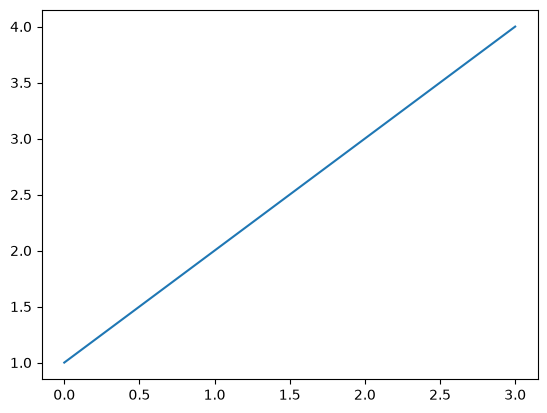

In [28]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3, 4])

plt.show()

**Nota sobre el PDF:** esta diapositiva (pág. 117) muestra el código y la 118 explica el resultado, pero ninguna muestra la imagen del gráfico. Es el comportamiento que se describe: x en 0-3 e y en 1-4.

Si se pasan los dos ejes:

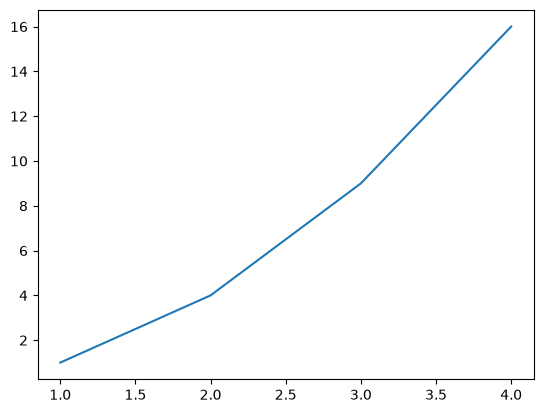

In [29]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3, 4], [1, 4, 9, 16])

plt.show()

Para personalizar el gráfico (ejemplo y = x² con x entre 0 y 99): `linewidth` ajusta el grosor de la línea, `color` el color, `plt.title()` agrega el título y `plt.xlabel()` / `plt.ylabel()` los nombres de los ejes.

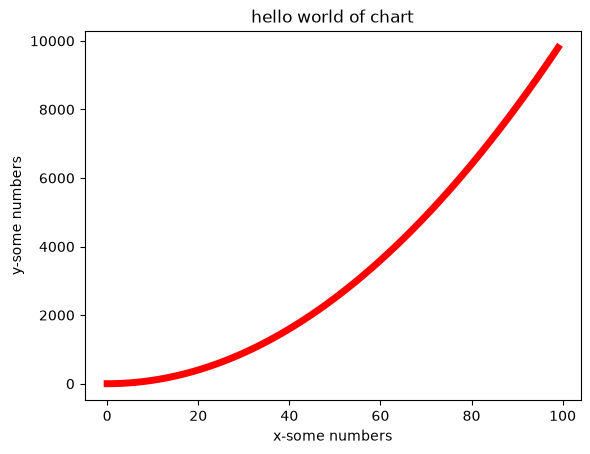

In [30]:
import matplotlib.pyplot as plt

x = range(100)
y = [value ** 2 for value in x]

plt.plot(x, y, linewidth=5.0, color='red')

plt.title('hello world of chart')
plt.ylabel('y-some numbers')
plt.xlabel('x-some numbers')

plt.show()

**Nota sobre el PDF:** la explicación de la pág. 121 dice que la línea 9 agrega el nombre del eje x y la línea 10 el del eje y, pero en el código la línea 9 es `plt.ylabel` (eje y) y la 10 es `plt.xlabel` (eje x). La descripción está invertida; el código es correcto. Además, las págs. 119–120 repiten la misma imagen, y la 120 no trae código.

**Referencia:** PDF parte 2, págs. 116–122

### Gráfico de barras

Un gráfico de barras representa cada valor con una barra rectangular cuya altura es proporcional a su tamaño. Permite comparar tamaños por la diferencia relativa de las alturas. Hay dos tipos:

| Barra vertical `plt.bar()` | Barra horizontal `plt.barh()` |
|---|---|
| Adecuada para mostrar diferencias entre dos puntos separados en el tiempo; es decir, para datos de series temporales. | Adecuada para mostrar diferencias entre los tamaños de variables distintas. |

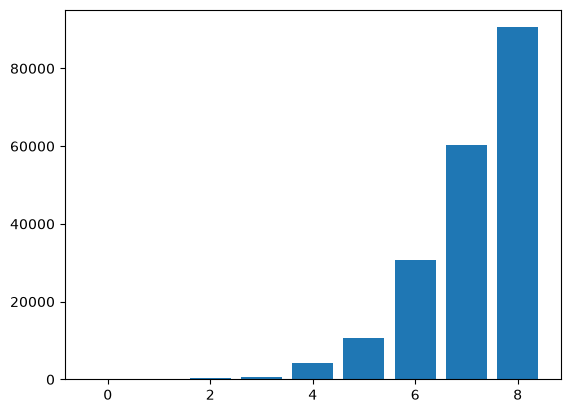

In [31]:
from matplotlib import pyplot as plt

days_in_year = [88, 225, 365, 687, 4333, 10756, 30687, 60190, 90553]

plt.bar(range(len(days_in_year)), days_in_year)

plt.show()

Los datos del ejemplo son la duración del año, en días terrestres, de los planetas del sistema solar (Mercurio, Venus, Tierra, Marte, Júpiter, Saturno, Urano, Neptuno y Plutón); el PDF solo muestra los números.

**Ampliación (no está en el PDF):** para rotular las barras, `plt.xticks(posiciones, etiquetas)` cambia los números del eje por nombres.

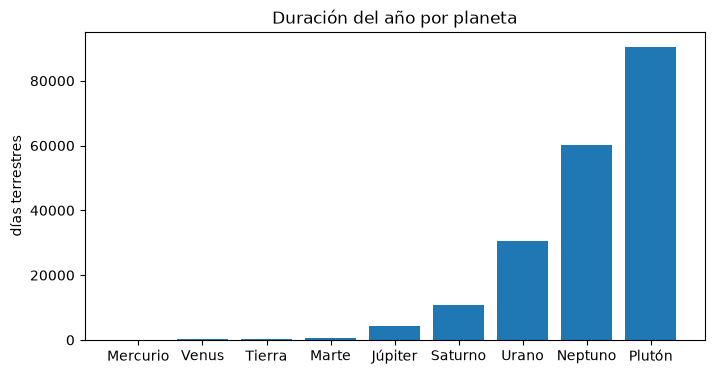

In [32]:
planetas = ['Mercurio', 'Venus', 'Tierra', 'Marte', 'Júpiter', 'Saturno', 'Urano', 'Neptuno', 'Plutón']

plt.figure(figsize=(8, 4))
plt.bar(planetas, days_in_year)
plt.title('Duración del año por planeta')
plt.ylabel('días terrestres')
plt.show()

**Ampliación (no está en el PDF):** el objetivo de la unidad menciona también el gráfico de **dispersión** (scatter). `plt.scatter(x, y)` dibuja un punto por pareja (x, y) y sirve para ver la relación entre dos variables numéricas; lo usaremos en el proyecto, con área y población de las ciudades.

**Clave:** barras verticales (`bar`) para series temporales; horizontales (`barh`) para comparar categorías con nombres largos.

**Referencia:** PDF parte 2, págs. 123–124

## Proyecto de la unidad: densidad de población de las ciudades más pobladas

**Problema:** con los datos de población 2020, población 2021 y área de las ciudades más pobladas, calcular la variación anual de población, la densidad de población, y encontrar las ciudades de mayor y menor densidad, con sus gráficos.

**Plan de programación (los pasos del PDF):**

1. Decidir qué bibliotecas se necesitan, instalarlas e importarlas: NumPy (arrays), pandas (series) y matplotlib (visualización).
2. Convertir los tres diccionarios en objetos Serie, comprobando que las etiquetas de índice coincidan entre sí.
3. Restar dos series para calcular la variación de población de cada ciudad.
4. Dibujar la variación en un gráfico de barras horizontales.
5. Calcular la densidad de población (`población / área`) y graficarla.
6. Encontrar las ciudades de mayor y menor densidad con las estadísticas descriptivas.

### Primer paso: bibliotecas y datos

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
# population_2020 es un objeto de datos de diccionario que almacena la población total en 2020.
population_2020 = {'Tokyo': 37339804,
                   'Delhi': 31181376,
                   'Shanghai': 27795702,
                   'Sao Paulo': 22237472,
                   'Mexico City': 21918936,
                   'Dhaka': 21741090,
                   'Cairo': 21322750,
                   'Karachi': 16459472,
                   'Istanbul': 15415197,
                   'Buenos Aires': 15257673,
                   'Kinshasa': 14970460,
                   'Lagos': 14862111,
                   'Manila': 14158573,
                   'Rio de Janeiro': 13544462,
                   'Moscow': 12593252,
                   'Bogota': 11167392,
                   'Paris': 11078546,
                   'Jakarta': 10915364,
                   'Lima': 10882757}

In [35]:
# population_2021 es un objeto de datos de diccionario que almacena la población total en 2021.
population_2021 = {'Tokyo': 37393128,
                   'Delhi': 30290936,
                   'Shanghai': 27058480,
                   'Sao Paulo': 22043028,
                   'Mexico City': 21782378,
                   'Dhaka': 21005860,
                   'Cairo': 20900604,
                   'Karachi': 16093786,
                   'Istanbul': 15190336,
                   'Buenos Aires': 15153729,
                   'Kinshasa': 14342439,
                   'Lagos': 14368332,
                   'Manila': 13923452,
                   'Rio de Janeiro': 13458075,
                   'Moscow': 12537954,
                   'Bogota': 10978360,
                   'Paris': 11017230,
                   'Jakarta': 10770487,
                   'Lima': 10719188}

In [36]:
# city_area son los datos de área de cada ciudad, y la unidad es km2.
city_area = {'Tokyo': 2194,
             'Delhi': 1484,
             'Shanghai': 6340,
             'Sao Paulo': 1521,
             'Mexico City': 1485,
             'Dhaka': 306.4,
             'Cairo': 3085,
             'Karachi': 3780,
             'Istanbul': 5343,
             'Buenos Aires': 203,
             'Kinshasa': 9965,
             'Lagos': 1171,
             'Manila': 42.88,
             'Rio de Janeiro': 1255,
             'Moscow': 2511,
             'Bogota': 1775,
             'Paris': 105.4,
             'Jakarta': 661.5,
             'Lima': 2672}

Los datos son los de las págs. 81–83. Convertimos cada diccionario en una serie y revisamos que el índice coincida (si las etiquetas o la cantidad de datos difieren, la aritmética devolvería `NaN`):

In [37]:
s_2020 = pd.Series(population_2020)
s_2021 = pd.Series(population_2021)
s_area = pd.Series(city_area)

print(len(s_2020), len(s_2021), len(s_area))
print(s_2020.index.equals(s_2021.index) and s_2020.index.equals(s_area.index))
print(s_2020.head())

19 19 19
True
Tokyo          37339804
Delhi          31181376
Shanghai       27795702
Sao Paulo      22237472
Mexico City    21918936
dtype: int64


### Paso 2: variación de población

Restar dos series calcula, ciudad por ciudad (etiqueta de índice), la diferencia entre los dos años.

In [38]:
growth = s_2020 - s_2021
print(growth)

Tokyo             -53324
Delhi             890440
Shanghai          737222
Sao Paulo         194444
Mexico City       136558
Dhaka             735230
Cairo             422146
Karachi           365686
Istanbul          224861
Buenos Aires      103944
Kinshasa          628021
Lagos             493779
Manila            235121
Rio de Janeiro     86387
Moscow             55298
Bogota            189032
Paris              61316
Jakarta           144877
Lima              163569
dtype: int64


**Nota sobre el PDF:** `s_2020 - s_2021` es la población de 2020 **menos** la de 2021, es decir, la variación con el signo invertido: un valor positivo significa que la ciudad perdió habitantes y uno negativo (como Tokyo, -53324) que ganó. Para obtener el crecimiento con el signo natural hay que restar al revés. Con los datos del PDF, la mayoría de las ciudades pierden población y solo Tokyo crece.

In [39]:
cambio = s_2021 - s_2020          # variación 2021 respecto de 2020 (positivo = crece)
print(cambio.head(3))
print("Ciudades que crecen:", cambio[cambio > 0].index.tolist())

Tokyo        53324
Delhi      -890440
Shanghai   -737222
dtype: int64
Ciudades que crecen: ['Tokyo']


### Paso 3: gráfico de barras horizontales

El PDF explica que el gráfico vertical es adecuado para datos de series temporales con valores consecutivos, pero que aquí conviene el **horizontal**, porque compara la diferencia entre variables (los nombres de ciudad). Para dibujarlo se extraen el índice (`x`) y los valores (`y`) de la serie.

In [40]:
x = growth.index
y = growth.values
print(list(x)[:3], list(y)[:3])

['Tokyo', 'Delhi', 'Shanghai'] [np.int64(-53324), np.int64(890440), np.int64(737222)]


`plt.figure(figsize=(ancho, alto))` ajusta el tamaño en pulgadas (por defecto 6.4 x 4.8), para evitar que los nombres se solapen. `plt.xticks(rotation=..., size=...)` rota los rótulos del eje y fija su tamaño de fuente (`rotation='vertical'` equivale a 90 grados, en sentido contrario a las agujas del reloj). `plt.barh()` traza las barras horizontales.

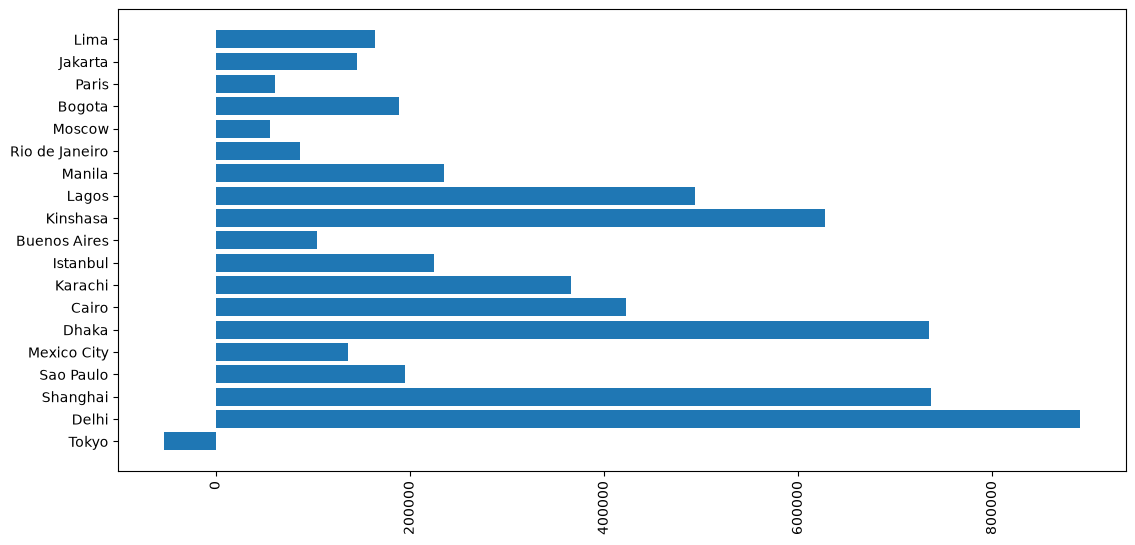

In [41]:
plt.figure(figsize=(13, 6))

plt.xticks(rotation='vertical', size=10)

plt.barh(x, y)

plt.show()

**Nota sobre el PDF:** el PDF concluye que "la tasa de crecimiento demográfico disminuye en Tokio". Con el signo de `s_2020 - s_2021` ocurre lo contrario: Tokyo es la única barra negativa, o sea la única ciudad que **creció**, mientras que las demás perdieron población (barra positiva). Con el cálculo corregido, el gráfico queda así, con título y nombres de ejes:

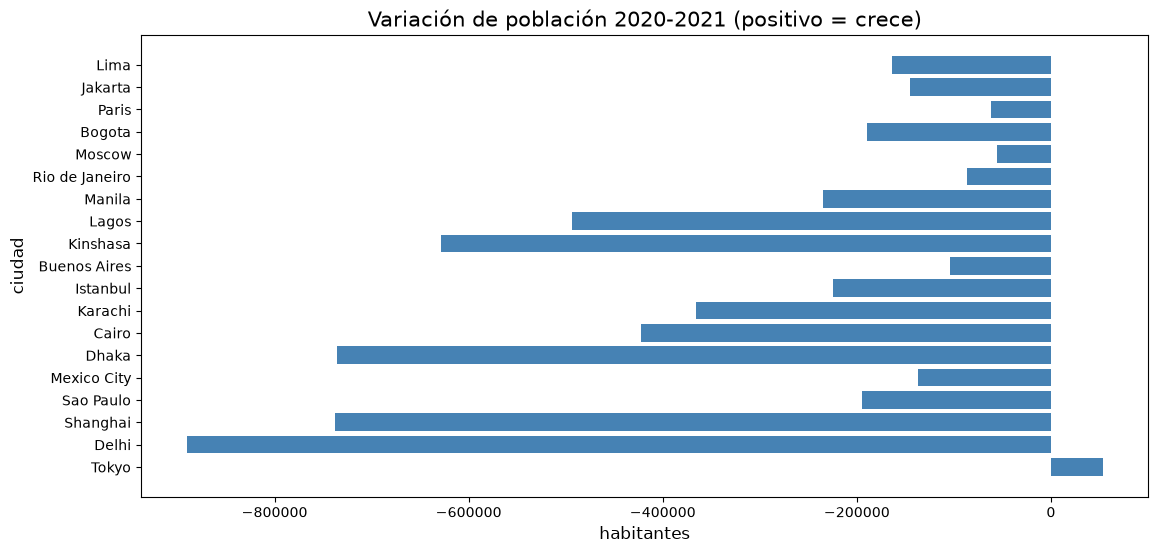

In [42]:
plt.figure(figsize=(13, 6))
plt.barh(cambio.index, cambio.values, color='steelblue')
plt.title('Variación de población 2020-2021 (positivo = crece)', size=15)
plt.xlabel('habitantes', size=12)
plt.ylabel('ciudad', size=12)
plt.show()

### Paso 4: densidad de población

Se divide la serie de población 2020 (`s_2020`) por la de área (`s_area`). Como ambas comparten las mismas etiquetas, la división se hace ciudad por ciudad.

In [43]:
population_density = s_2020 / s_area
population_density

Tokyo              17019.053783
Delhi              21011.708895
Shanghai            4384.180126
Sao Paulo          14620.297173
Mexico City        14760.226263
Dhaka              70956.560052
Cairo               6911.750405
Karachi             4354.357672
Istanbul            2885.120157
Buenos Aires       75160.950739
Kinshasa            1502.304064
Lagos              12691.811272
Manila            330190.601679
Rio de Janeiro     10792.400000
Moscow              5015.233771
Bogota              6291.488451
Paris             105109.544592
Jakarta            16500.928193
Lima                4072.888099
dtype: float64

In [44]:
x = population_density.index
y = population_density.values

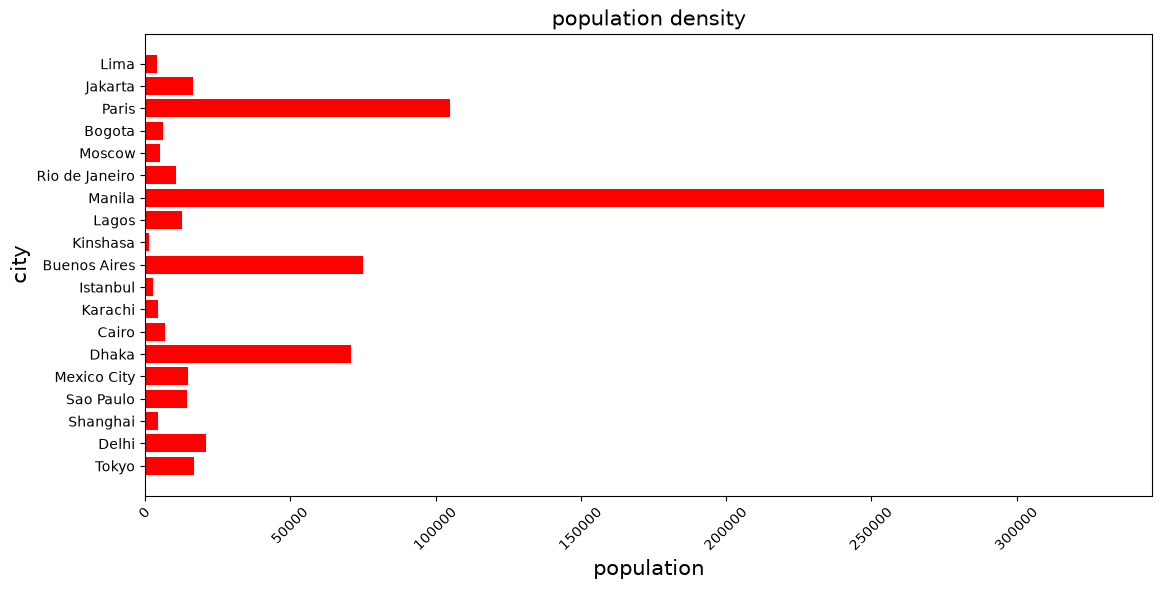

In [45]:
plt.figure(figsize=(13, 6))

plt.xticks(rotation=45, size=10)

plt.barh(x, y, color='red')

plt.title('population density', size=15)
plt.ylabel('city', size=15)
plt.xlabel('population', size=15)

plt.show()

**Nota sobre el PDF:** el eje x de este gráfico mide **habitantes por km²** (densidad), pero el PDF lo rotula "population". Una versión con rótulos correctos y las ciudades ordenadas (ampliación) facilita la lectura:

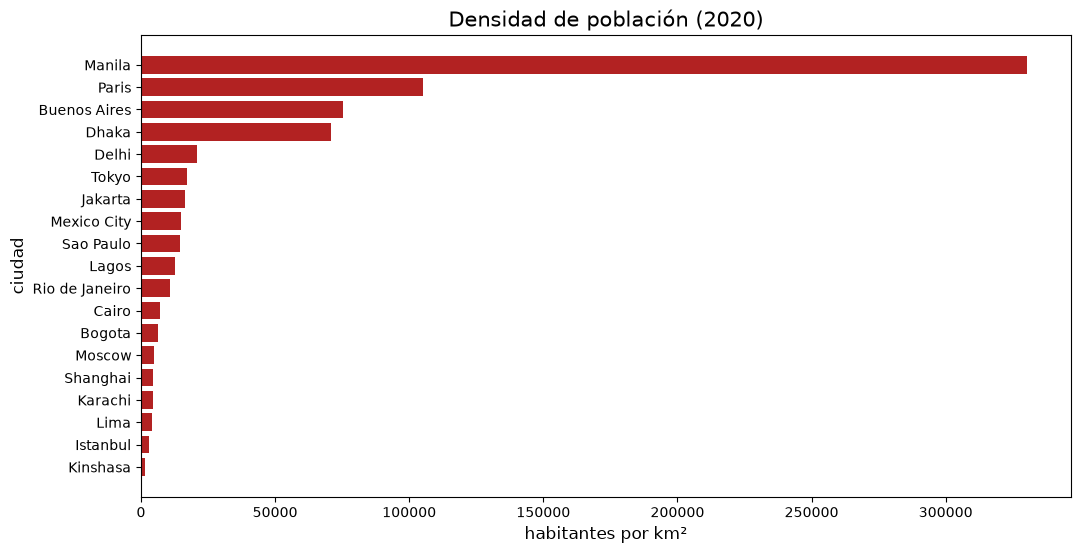

In [46]:
ordenada = population_density.sort_values()

plt.figure(figsize=(12, 6))
plt.barh(ordenada.index, ordenada.values, color='firebrick')
plt.title('Densidad de población (2020)', size=15)
plt.xlabel('habitantes por km²', size=12)
plt.ylabel('ciudad', size=12)
plt.show()

### Paso 5: ciudades de mayor y menor densidad

Con las estadísticas descriptivas de la serie: `min()` y `max()` dan los valores; `mean()` el promedio.

In [47]:
print(population_density.mean())
print(population_density.max())
print(population_density.min())

38117.44238880675
330190.60167910444
1502.3040642247868


**Nota sobre el PDF:** la pág. 139 anuncia "busca el valor mínimo" pero el código de esa diapositiva es `population_density.mean()` (el promedio, 38117.44...); el mínimo no aparece. Aquí se calcula con `min()`. Las págs. 138–139 repiten además la tabla de métodos con algunos nombres traducidos (`contar()`, `suma()`, `media()`, `mediana()`, `modo()`): en el código real son `count()`, `sum()`, `mean()`, `median()` y `mode()`.

`max()` y `min()` devuelven solo el número. Para saber **qué ciudad** es, se usa `idxmax()` e `idxmin()` (ampliación):

In [48]:
print("Mayor densidad:", population_density.idxmax(), round(population_density.max(), 2))
print("Menor densidad:", population_density.idxmin(), round(population_density.min(), 2))

Mayor densidad: Manila 330190.6
Menor densidad: Kinshasa 1502.3


**Resultado esperado:** la mayor densidad es la de Manila (unos 330 190 hab/km²) y la menor la de Kinshasa (unos 1502 hab/km²); el promedio es de unos 38 117 hab/km².

**Ampliación (no está en el PDF):** la densidad de Manila es tan alta porque el área del diccionario (42.88 km²) corresponde a la ciudad propiamente dicha, no a su área metropolitana, mientras que la población y el área de otras ciudades (por ejemplo Tokyo) se refieren a áreas metropolitanas. Los datos no son comparables del todo: al interpretar un resultado hay que revisar de dónde vienen las cifras.

**Ampliación (no está en el PDF):** gráfico de dispersión de área contra población; cada punto es una ciudad.

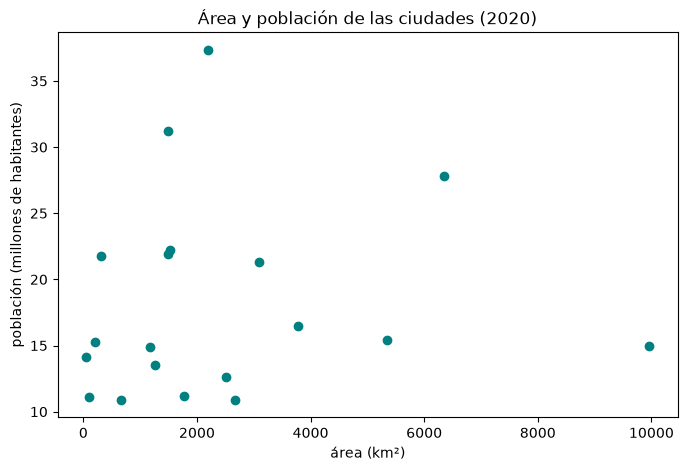

In [49]:
plt.figure(figsize=(8, 5))
plt.scatter(s_area.values, s_2020.values / 1_000_000, color='teal')
plt.title('Área y población de las ciudades (2020)')
plt.xlabel('área (km²)')
plt.ylabel('población (millones de habitantes)')
plt.show()

**Referencia:** PDF parte 2, págs. 126–139

## Programación en pareja: lista de reproducción con Spotify

**Enunciado del PDF (pág. 143, Q1):** el conjunto de datos de Spotify tiene varios valores de columna aparte del nombre del artista, la clasificación y la popularidad que se usan en la misión. Discute con tu compañero de clase para crear una lista de reproducción especial hecha con otros valores de columna.

Las págs. 141–142 son texto general sobre la práctica de programación en pareja (acordar turnos para manejar el ratón, emparejar compañeros de habilidades similares, evitar el reparto "divide y vencerás", evitar trampas y trabajar en un entorno colaborativo).

**Nota sobre el PDF:** las págs. 141 y 142 tienen el texto en español y en inglés superpuesto y es parcialmente ilegible; el resumen anterior sale de las líneas que se distinguen. El conjunto de datos de Spotify de la misión no se incluye en esta unidad (el PDF lo carga con `pd.read_csv` en la Unidad 36).

**Datos usados aquí (no vienen en el PDF).** El PDF usa el archivo de Kaggle *Spotify Global 2019 Most Streamed Tracks*, que exige iniciar sesión en Kaggle para descargarlo. En su lugar se usa una copia pública con columnas equivalentes: el conjunto `spotify_songs` del proyecto TidyTuesday (semana del 21 de enero de 2020, https://github.com/rfordatascience/tidytuesday), que reúne canciones de Spotify con su popularidad y sus características de audio. Se conservaron las 150 canciones más populares (sin repetir título y artista) y solo las columnas necesarias; el archivo es `../datos/u35-spotify-canciones.csv`. No tiene una columna de clasificación ni la popularidad del artista del archivo original: aquí la popularidad es la de la **canción** (`track_popularity`).

In [50]:
canciones = pd.read_csv("../datos/u35-spotify-canciones.csv")
print(canciones.columns.tolist())
print(len(canciones))

['track_name', 'track_artist', 'track_popularity', 'playlist_genre', 'danceability', 'energy', 'valence', 'tempo', 'duration_ms']
150


El archivo se carga con `pd.read_csv` (en la Unidad 36 se estudia el DataFrame que devuelve). Para quedarnos con series, extraemos columnas y las indexamos por el nombre de la canción con su artista.

In [51]:
etiqueta = canciones['track_artist'] + ' - ' + canciones['track_name']

popularidad = pd.Series(canciones['track_popularity'].values, index=etiqueta.values)
bailable = pd.Series(canciones['danceability'].values, index=etiqueta.values)
energia = pd.Series(canciones['energy'].values, index=etiqueta.values)
tempo = pd.Series(canciones['tempo'].values, index=etiqueta.values)

print(popularidad.head())
print("Popularidad media:", round(popularidad.mean(), 2))
print("Más popular:", popularidad.idxmax(), popularidad.max())

The Weeknd - Blinding Lights    98
Maroon 5 - Memories             98
Roddy Ricch - The Box           98
KAROL G - Tusa                  98
Dua Lipa - Don't Start Now      97
dtype: int64
Popularidad media: 88.51
Más popular: The Weeknd - Blinding Lights 98


**Idea de lista especial (ampliación):** una lista "para entrenar" con canciones de alta energía y alto tempo. Una serie se puede filtrar con una condición lógica: `serie[serie > valor]`; se combinan condiciones con `&` y paréntesis, y se ordena con `sort_values()`.

In [52]:
entrenar = (energia > 0.8) & (tempo > 120)
lista = energia[entrenar].sort_values(ascending=False)

print(len(lista), "canciones")
print(lista.head(8))

6 canciones
Kanye West - Follow God                     0.900
Pedro Sampaio - SENTADÃO                    0.869
Calvin Harris - One Kiss (with Dua Lipa)    0.862
Camilo - Tutu                               0.832
Riton - Turn Me On (feat. Vula)             0.828
Rich Music LTD - Quizas                     0.815
dtype: float64


In [53]:
# Otra lista: las más bailables entre las canciones muy populares
muy_populares = popularidad[popularidad >= 90].index
fiesta = bailable[muy_populares].nlargest(5)
print(fiesta)

Roddy Ricch - The Box                 0.896
Bad Bunny - Vete                      0.886
Lil Uzi Vert - Futsal Shuffle 2020    0.881
Regard - Ride It                      0.880
Rauw Alejandro - Fantasias            0.879
dtype: float64


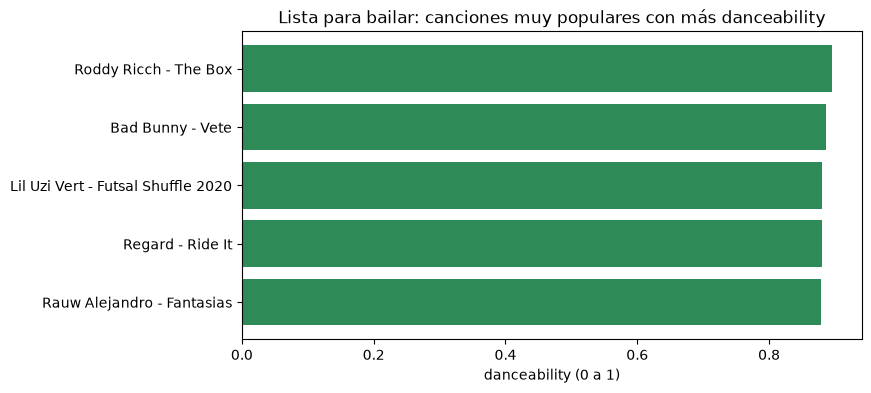

In [54]:
plt.figure(figsize=(8, 4))
plt.barh(fiesta.index[::-1], fiesta.values[::-1], color='seagreen')
plt.title('Lista para bailar: canciones muy populares con más danceability')
plt.xlabel('danceability (0 a 1)')
plt.show()

Para la actividad en pareja: elijan otra combinación de columnas (por ejemplo `valence` alta para una lista "alegre", o `duration_ms` baja para una lista "corta") y justifiquen en voz alta por qué ese criterio da una buena lista.

**Referencia:** PDF parte 2, págs. 140–143

## Práctica

Completa cada función y ejecuta la celda de verificación. Los ejercicios van de menor a mayor dificultad.

### Ejercicio 1 — Crear una serie con etiquetas

Escribe `crear_serie(valores, etiquetas)` que devuelva una serie de pandas con esos valores y esas etiquetas de índice.

In [55]:
def crear_serie(valores, etiquetas):
    # Escribe tu solución aquí
    pass

In [56]:
def partes(serie):
    # Devuelve (índice, valores) como listas; None si la función aún no devuelve una serie
    return None if serie is None else (serie.index.tolist(), serie.tolist())

verificar("serie 1", partes(crear_serie([10, 20, 30], ['a', 'b', 'c'])), (['a', 'b', 'c'], [10, 20, 30]))
verificar("serie 2", partes(crear_serie([1.5, 2.5], ['x', 'y'])), (['x', 'y'], [1.5, 2.5]))

Incorrecto: serie 1. Se esperaba (['a', 'b', 'c'], [10, 20, 30]) y se obtuvo None
Incorrecto: serie 2. Se esperaba (['x', 'y'], [1.5, 2.5]) y se obtuvo None


<details><summary>Ver solución</summary>

```python
def crear_serie(valores, etiquetas):
    return pd.Series(valores, index=etiquetas)
```

El parámetro `index` de `pd.Series` asigna las etiquetas.
</details>

### Ejercicio 2 — Seleccionar por etiqueta

Escribe `seleccionar(serie, etiquetas)` que devuelva, como lista de Python, los valores de la serie para las etiquetas indicadas (en ese orden).

In [57]:
def seleccionar(serie, etiquetas):
    # Escribe tu solución aquí
    pass

In [58]:
sr = pd.Series([5, 6, 7, 8], index=['a', 'b', 'c', 'd'])
verificar("dos etiquetas", seleccionar(sr, ['b', 'd']), [6, 8])
verificar("una etiqueta", seleccionar(sr, ['a']), [5])
verificar("orden pedido", seleccionar(sr, ['d', 'a']), [8, 5])

Incorrecto: dos etiquetas. Se esperaba [6, 8] y se obtuvo None
Incorrecto: una etiqueta. Se esperaba [5] y se obtuvo None
Incorrecto: orden pedido. Se esperaba [8, 5] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def seleccionar(serie, etiquetas):
    return serie.loc[etiquetas].tolist()
```

`serie.loc[lista]` selecciona varios elementos por etiqueta y respeta el orden pedido; `tolist()` convierte el resultado en una lista.
</details>

### Ejercicio 3 — Contar los NaN de una suma

Escribe `contar_nan(s1, s2)` que devuelva cuántos elementos `NaN` tiene la serie `s1 + s2` (entero).

In [59]:
def contar_nan(s1, s2):
    # Escribe tu solución aquí
    pass

In [60]:
verificar("índices distintos de largo", contar_nan(pd.Series([1, 2, 3, 4]), pd.Series([10, 20])), 2)
verificar("etiquetas desalineadas", contar_nan(pd.Series([1, 2], index=['a', 'b']), pd.Series([1, 2], index=['b', 'c'])), 2)
verificar("mismo índice", contar_nan(pd.Series([1, 2]), pd.Series([3, 4])), 0)

Incorrecto: índices distintos de largo. Se esperaba 2 y se obtuvo None
Incorrecto: etiquetas desalineadas. Se esperaba 2 y se obtuvo None
Incorrecto: mismo índice. Se esperaba 0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def contar_nan(s1, s2):
    return int((s1 + s2).isna().sum())
```

`isna()` marca los `NaN` con `True`; `sum()` cuenta los `True`. `int()` convierte el resultado a un entero de Python.
</details>

### Ejercicio 4 — Estadísticas básicas

Escribe `estadisticas(serie)` que devuelva un diccionario con las claves `'media'`, `'mediana'`, `'maximo'` y `'minimo'` de la serie.

In [61]:
def estadisticas(serie):
    # Escribe tu solución aquí
    pass

In [62]:
verificar("serie 1", estadisticas(pd.Series([1, 2, 3, 4, 10])),
          {'media': 4.0, 'mediana': 3.0, 'maximo': 10, 'minimo': 1})
verificar("serie 2", estadisticas(pd.Series([5, 5, 5])),
          {'media': 5.0, 'mediana': 5.0, 'maximo': 5, 'minimo': 5})

Incorrecto: serie 1. Se esperaba {'media': 4.0, 'mediana': 3.0, 'maximo': 10, 'minimo': 1} y se obtuvo None
Incorrecto: serie 2. Se esperaba {'media': 5.0, 'mediana': 5.0, 'maximo': 5, 'minimo': 5} y se obtuvo None


<details><summary>Ver solución</summary>

```python
def estadisticas(serie):
    return {'media': float(serie.mean()), 'mediana': float(serie.median()),
            'maximo': serie.max().item(), 'minimo': serie.min().item()}
```

Los métodos `mean()`, `median()`, `max()` y `min()` calculan cada valor; `item()` y `float()` devuelven números de Python para compararlos con facilidad.
</details>

### Ejercicio 5 — Densidad redondeada

Escribe `densidad(poblacion, area)` que reciba dos diccionarios con las mismas claves y devuelva una lista con las densidades (población / área) redondeadas a 1 decimal, en el orden de los diccionarios.

In [63]:
def densidad(poblacion, area):
    # Escribe tu solución aquí
    pass

In [64]:
verificar("dos ciudades", densidad({'A': 1000, 'B': 500}, {'A': 10, 'B': 40}), [100.0, 12.5])
verificar("una ciudad", densidad({'X': 100}, {'X': 3}), [33.3])

Incorrecto: dos ciudades. Se esperaba [100.0, 12.5] y se obtuvo None
Incorrecto: una ciudad. Se esperaba [33.3] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def densidad(poblacion, area):
    return (pd.Series(poblacion) / pd.Series(area)).round(1).tolist()
```

Se convierten los diccionarios en series, se dividen (se alinean por etiqueta) y se redondea con `round(1)`.
</details>

### Ejercicio 6 — Ciudad más densa

Escribe `ciudad_mas_densa(poblacion, area)` que devuelva el nombre de la ciudad con mayor densidad de población.

In [65]:
def ciudad_mas_densa(poblacion, area):
    # Escribe tu solución aquí
    pass

In [66]:
verificar("caso 1", ciudad_mas_densa({'A': 1000, 'B': 500}, {'A': 10, 'B': 2}), 'B')
verificar("caso 2", ciudad_mas_densa({'A': 900, 'B': 500, 'C': 300}, {'A': 3, 'B': 5, 'C': 10}), 'A')
verificar("con los datos de la unidad", ciudad_mas_densa(population_2020, city_area), 'Manila')

Incorrecto: caso 1. Se esperaba 'B' y se obtuvo None
Incorrecto: caso 2. Se esperaba 'A' y se obtuvo None
Incorrecto: con los datos de la unidad. Se esperaba 'Manila' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def ciudad_mas_densa(poblacion, area):
    return (pd.Series(poblacion) / pd.Series(area)).idxmax()
```

`idxmax()` devuelve la etiqueta del valor máximo; `max()` devolvería solo el número.
</details>

### Ejercicio 7 — Serie diaria con fechas

Escribe `serie_con_fechas(valores, inicio)` que devuelva una serie cuyo índice sean fechas diarias consecutivas desde `inicio` (texto `'AAAA-MM-DD'`), una por valor.

In [67]:
def serie_con_fechas(valores, inicio):
    # Escribe tu solución aquí
    pass

In [68]:
def partes(serie):
    # Devuelve (fechas como texto, valores); None si la función aún no devuelve una serie
    return None if serie is None else ([str(f.date()) for f in serie.index], serie.tolist())

verificar("tres días", partes(serie_con_fechas([5, 6, 7], '2021-01-01')), (['2021-01-01', '2021-01-02', '2021-01-03'], [5, 6, 7]))
verificar("cruce de mes", partes(serie_con_fechas([1, 2], '2021-01-31')), (['2021-01-31', '2021-02-01'], [1, 2]))

Incorrecto: tres días. Se esperaba (['2021-01-01', '2021-01-02', '2021-01-03'], [5, 6, 7]) y se obtuvo None
Incorrecto: cruce de mes. Se esperaba (['2021-01-31', '2021-02-01'], [1, 2]) y se obtuvo None


<details><summary>Ver solución</summary>

```python
def serie_con_fechas(valores, inicio):
    fechas = pd.date_range(inicio, periods=len(valores))
    return pd.Series(valores, index=fechas)
```

`pd.date_range(inicio, periods=n)` crea `n` fechas diarias; así la longitud del índice coincide con la de los datos.
</details>

### Ejercicio 8 — Canciones por encima de un umbral

Escribe `populares(serie, minimo)` que devuelva la lista de etiquetas cuyo valor es mayor o igual que `minimo`, ordenadas de mayor a menor valor. (Filtrado lógico: ampliación.)

In [69]:
def populares(serie, minimo):
    # Escribe tu solución aquí
    pass

In [70]:
pop = pd.Series([90, 70, 85, 95], index=['a', 'b', 'c', 'd'])
verificar("umbral 85", populares(pop, 85), ['d', 'a', 'c'])
verificar("umbral 96", populares(pop, 96), [])
verificar("umbral 0", populares(pop, 0), ['d', 'a', 'c', 'b'])

Incorrecto: umbral 85. Se esperaba ['d', 'a', 'c'] y se obtuvo None
Incorrecto: umbral 96. Se esperaba [] y se obtuvo None
Incorrecto: umbral 0. Se esperaba ['d', 'a', 'c', 'b'] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def populares(serie, minimo):
    return serie[serie >= minimo].sort_values(ascending=False).index.tolist()
```

`serie >= minimo` genera una serie de booleanos; usarla como índice filtra; `sort_values(ascending=False)` ordena de mayor a menor.
</details>

## Apuntes para estudiar

**Clave**

- Pandas es una biblioteca de operación y análisis de datos; se importa como `import pandas as pd` y se instala con `pip` (o `uv`) en el entorno que se está usando.
- Serie = estructura unidimensional con índice y datos (relación 1:1); DataFrame = estructura bidimensional (índice y columnas).
- Una serie se crea desde una lista, un diccionario (claves = índice), un array de NumPy o un escalar; el índice por defecto es entero desde 0 y se cambia con `index=`.
- `serie.index` da los índices y `serie.values` los datos. Selección: `sr[2]`, `sr[[4, 5]]` (entero) y `sr['c']`, `sr[['e', 'f']]` (etiqueta).
- Las operaciones entre series se alinean por índice; lo que no tiene pareja es `NaN`, y el resultado pasa a `float64`.
- Estadísticas: `count`, `sum`, `mean`, `median`, `mode`, `std`, `min`, `max`, `abs`, `prod`, `cumsum`, `cumprod`.
- Matplotlib: `plt.plot` (líneas), `plt.bar` (barras verticales, series temporales), `plt.barh` (barras horizontales, comparar categorías), `plt.scatter` (dispersión). `plt.show()` lo muestra.

**Errores comunes**

- `ImportError` por instalar pandas en un Python distinto del que ejecuta el código.
- Pasar un índice con distinta longitud que los datos: `ValueError`.
- Sumar series con índices distintos y no notar los `NaN` del resultado.
- Seleccionar varios elementos sin lista (`sr[4, 5]` en vez de `sr[[4, 5]]`).
- Restar en el orden equivocado: `s_2020 - s_2021` invierte el signo de la variación.
- Confundir `max()` (valor) con `idxmax()` (etiqueta).

**Para el quiz**

- Diferencia Serie / DataFrame (1D contra 2D).
- Qué devuelve `pd.Series({'a': 1, 'b': 2}).index`: las claves del diccionario.
- Qué resulta de sumar dos series con índices parcialmente distintos: `NaN` en las posiciones sin pareja.
- `count()` ignora los `NaN`; `sum()` también los ignora.
- Qué gráfico usar: barras verticales para series temporales, horizontales para comparar variables.
- `pd.date_range('2021-01-01', '2021-01-07')` crea un `DatetimeIndex` de 7 días.

## Autoevaluación

**1. ¿En qué se diferencia una Serie de un array de NumPy?**

<details><summary>Ver respuesta</summary>

La Serie tiene un índice: cada dato lleva asociada una etiqueta (por defecto un entero desde 0), lo que permite seleccionar, alinear y operar por etiqueta. El array de NumPy solo se accede por posición.
</details>

**2. ¿Qué serie crea `pd.Series({'Iron Man': 2010, 'Thor': 2013})` y qué papel cumplen claves y valores?**

<details><summary>Ver respuesta</summary>

Una serie con dos elementos: las claves del diccionario ('Iron Man', 'Thor') pasan a ser el índice y los valores (2010, 2013) pasan a ser los datos.
</details>

**3. Si `a = pd.Series([1, 2, 3])` y `b = pd.Series([10, 20])`, ¿qué resulta de `a + b` y por qué?**

<details><summary>Ver respuesta</summary>

`[11.0, 22.0, NaN]`. Pandas empareja por índice; el índice 2 solo existe en `a`, así que no tiene pareja y da `NaN`. Por el `NaN`, el resultado pasa a tipo `float64`.
</details>

**4. ¿Cuándo conviene `plt.bar()` y cuándo `plt.barh()`?**

<details><summary>Ver respuesta</summary>

`bar()` (vertical) conviene para datos de series temporales, es decir, valores en momentos distintos; `barh()` (horizontal) conviene para comparar el tamaño de variables distintas, sobre todo si sus nombres son largos, como los de las ciudades.
</details>

**5. Con `densidad = poblacion / area`, ¿cómo obtienes el nombre de la ciudad más densa y no solo su valor?**

<details><summary>Ver respuesta</summary>

Con `densidad.idxmax()`, que devuelve la etiqueta del índice del valor máximo. `densidad.max()` solo devuelve el número.
</details>

---

[Índice de la semana](../semana-05.ipynb) | [Anterior](u34-modulos-de-python.ipynb) | [Siguiente](u36-dataframes-de-pandas.ipynb)